# Our method at depth: 2-task multi-MNIST with 2 to 4 hidden layers

With more hidden layers, does our method still do as well as this architecture allows? We train it on deeper
networks, fully connected and block-sparse, and compare it with SGD tuned on each network at each depth. Part 2 asks
whether generate and test across all hidden layers, alone or with shadow weights, recovers block-sparse performance at
depth.

**Problem.** 2-task multi-MNIST exactly as in `../05_multi_mnist.ipynb`: each sample concatenates 2 independently drawn
training images (14×14, averaged 2×2 blocks; each pixel centered, all scaled by one standard deviation), and each
task's target is its own image's label. Every 1000 steps, one task (chosen at random) gets a new random mapping from
digits to labels. The loss is the sum of each task's softmax cross-entropy.

**Networks.** 3, 4 and 5 weight layers: 392 inputs → 2, 3 or 4 hidden layers of 20 LTUs → 20 linear outputs (2 groups
of 10 logits), every layer with a bias.
- *Fully connected*: every unit reads every unit of the layer below.
- *Block-sparse*: every layer is block-diagonal, so each task has its own column of 10 units through all hidden layers:
  the first reads only its task's image, and the last feeds only its task's logits (05's ideal connectivity, deeper).

**Learners.**
- *Ours*, at depth. Every hidden layer is centered: it sends $h - m$, $m$ its own running mean firing rates (rate
  $10^{-3}$, starting at 1/2). Every hidden layer's input weights are backward centered as in 05: each one's derivative
  is $\sigma'(z)\,x - \mathbb{E}[\sigma'(z)\,x]$, with a running mean per layer, $x$ that layer's input including the
  bias (the centered output of the layer below). Every hidden layer's input weights start at $U(-\alpha_0, \alpha_0)$;
  output weights and biases start at 0. Autostep ($\alpha_0 = 10^{-8}$, meta step-size 0.01, $\tau = 10^4$) treats
  each layer as its own linear problem, its source values that layer's input.
- *SGD*, the standard setup: raw hidden units $h$, LeCun-uniform input weights at every hidden layer, output weights and
  biases at 0, one constant step size. It is tuned separately at each depth and on each network: 5 seeds per step
  size, over powers of 2, by the accuracy below. Each grid is extended one power of 2 at a time past whichever edge
  holds its best value, until the best has a worse value on both sides.

Per-layer backward centering removes the mean push on each layer's own input weights exactly (`../01_distractors.ipynb`,
3c). The gradient passed down to lower layers is centered only up to a covariance term: through upper unit $j$, a
lower weight $w'_{ki}$ gets $\delta_j\,\sigma'(z_j)\,w_{jk}\,(\sigma'(z'_k)\,x'_i - \mathbb{E}[\sigma'(z'_k)\,x'_i])$,
whose mean under a constant error $\delta_j$ is $\delta_j\,w_{jk}\,\mathrm{Cov}(\sigma'(z_j), \sigma'(z'_k)\,x'_i)$,
not 0. But with all weights near $10^{-8}$ early, the gradients reaching lower layers are tiny in the phase where the
mean push mattered (`../01_distractors.ipynb`, 3b).

At each depth: ours and SGD (at its best step size for that network) on both networks. 1000k steps;
seed $s$ gives every run the same initial-weight draw, images and label changes.

**Hypotheses**, on the online accuracy (over every task) averaged over the last 10% of training, as gaps on paired
seeds (mean ± 2 SE):
- **H1**, depth does not bring back mixing: at every depth, ours fully connected is at most 1 percentage point below
  ours block-sparse.
- **H2**, ours does as well as the architecture allows: at every depth, ours block-sparse is at most 1 percentage point
  below SGD block-sparse.
- **H3**, density also costs SGD: at every depth, SGD fully connected is more than 1 percentage point below SGD
  block-sparse.

**Part 2.** Does generate and test across all hidden layers, alone or with shadow weights, recover block-sparse
performance at depth? At each depth, two more runs of ours on the fully connected network, compared with Part 1's ours
fully connected and block-sparse:
- *Generate and test*, at every hidden layer independently: every 100k steps, in each hidden layer, the unit with the
  smallest mean $|$outgoing weight$|$ (into the layer above, or into the outputs) starts over as a new unit: incoming
  weights $U(-\alpha_0, \alpha_0)$, outgoing weights 0, step-sizes $\alpha_0$, zero Autostep traces, and its running
  mean and backward-centering slopes (of its incoming and outgoing weights) at their initial values. One unit per layer
  per reset, as in 05.
- *Generate and test + shadow weights*: also, every hidden unit is paired with a randomly chosen unit in the layer
  above (a random output for the last hidden layer) and a random ±1 shadow weight. In the backward pass a unit hears
  from every unit above through the real weights, except that the weight from its paired unit counts as its shadow
  weight unless the real one is larger in magnitude: the output-layer shadow weights of `shadow_weights.ipynb`, here
  at every layer. The forward pass is unchanged. A reset unit also gets a new random pairing and sign.

On the same accuracy:
- **H4**, generate and test helps at depth: at every depth, it raises ours fully connected by more than 1 percentage
  point.
- **H5**, with shadow weights it recovers block-sparse performance: at every depth, ours fully connected with generate
  and test + shadow weights is at most 1 percentage point below ours block-sparse.

**Diagnostics**, fixed in advance, for every run of both parts:
1. *Path purity*, end to end: the share of all input → … → output path weight (the product of $|w|$ along the path)
   that starts and ends in the same task. 1 means no path crosses tasks; 1/2 that the paths mix the tasks evenly. It
   is 1 by construction on the block-sparse network. Pooling over all paths means a task with almost no paths barely
   counts.
2. *Per-task accuracy*: each task's online accuracy, recorded per window. Reported per run as each
   task's accuracy over the last 10% of training (mean over seeds), and the number of seeds in which a task stays
   near chance (below 15% over the last 10%; chance is 10%).

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Networks ---
DEPTHS = (3, 4, 5)                   # weight layers: 2, 3 and 4 hidden layers
N_HIDDEN_PER_TASK = 10               # every hidden layer has 10 units per task, 20 in total

# --- Autostep (ours) ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means

# --- SGD ---
SGD_EXPONENTS = range(-8, 1)         # each network's sweep starts at 2^-8 ... 2^0, and grows past an edge with its best
SWEEP_SEEDS = 5                      # seeds per step size in the sweeps

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 5
N_WINDOWS = 250                      # each window records its mean loss and accuracy, and the path purity at its end

# --- Generate and test (Part 2) ---
RESET_PERIOD = 100_000               # steps between generate-and-test resets (one unit per hidden layer)

# --- Diagnostics ---
NEAR_CHANCE = 0.15                   # a task below this accuracy over the last 10% stays near chance (10%)

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
NETWORKS = ('fully connected', 'block-sparse')


def network_masks(n_layers, network):
    # Each layer's mask, shaped like its weight matrix (units, inputs + 1); the last column reads the constant-1 input.
    # Block-sparse: a unit reads only the units of its own task in the layer below.
    sizes = [N_PIXELS] + [N_HIDDEN_PER_TASK] * (n_layers - 1) + [N_CLASSES]       # per task, from inputs to outputs
    tasks = [np.repeat(np.arange(N_TASKS), n) for n in sizes]
    return [np.concatenate([(out[:, None] == inp[None, :]) | (network == 'fully connected'),
                            np.ones((len(out), 1), bool)], 1)
            for inp, out in zip(tasks[:-1], tasks[1:])]


for n_layers in DEPTHS:
    for network in NETWORKS:
        weights = ', '.join(f'{m[:, :-1].sum():,}' for m in network_masks(n_layers, network))
        print(f'{n_layers} layers, {network}: {weights} weights')

3 layers, fully connected: 7,840, 400, 400 weights
3 layers, block-sparse: 3,920, 200, 200 weights
4 layers, fully connected: 7,840, 400, 400, 400 weights
4 layers, block-sparse: 3,920, 200, 200, 200 weights
5 layers, fully connected: 7,840, 400, 400, 400, 400 weights
5 layers, block-sparse: 3,920, 200, 200, 200, 200 weights


## Learners

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: list                   # each layer's weights; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState            # Autostep's state (unused by SGD)
    hidden_mean: list         # each hidden layer's running mean firing rates
    hidden_slope: list        # each hidden layer's running mean of sigma'(z) x, its derivative w.r.t. each input weight
    pair: list                # each hidden unit's paired unit in the layer above, for shadow weights (Part 2) ...
    sign: list                # ... and its fixed +-1 shadow weight from that unit


def init_learner(key, masks, ours):
    # Every hidden layer's input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's
    # inputs for SGD. Both scale the same draw. Biases and output weights start at 0.
    w = []
    for layer_key, mask in zip(jax.random.split(key, len(masks) - 1), masks[:-1]):
        bound = INIT_STEP_SIZE if ours else jnp.sqrt(3.0 / mask[:, :-1].sum(1, keepdims=True))
        w.append((jax.random.uniform(layer_key, mask.shape, minval=-1.0, maxval=1.0) * bound * mask).at[:, -1].set(0.0))
    w.append(jnp.zeros(masks[-1].shape))
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs (the centered units below, for ours), 1/4 for the bias.
    # Shadow weights: each hidden unit is paired with a unit of the layer above drawn at random, with a random sign.
    hidden = [m.shape[0] for m in masks[:-1]]
    pair_keys, sign_keys = (jax.random.split(jax.random.fold_in(key, i), len(hidden)) for i in (1, 2))
    pair = [jax.random.randint(k, (n,), 0, above.shape[0]) for k, n, above in zip(pair_keys, hidden, masks[1:])]
    sign = [jax.random.rademacher(k, (n,), dtype=jnp.float32) for k, n in zip(sign_keys, hidden)]
    return Learner(w, OPTIMIZER.init(w), [jnp.full(n, 0.5) for n in hidden],
                   [jnp.zeros(m.shape).at[:, -1].set(0.25) for m in masks[:-1]], pair, sign)


def shadowed(weights, x, pair, sign):
    # weights @ x, x a hidden layer's output with the bias. Shadow weights: x's gradient comes through a fixed copy of
    # the weights, in which the weight from each unit's paired unit above counts as its +-1 shadow weight unless the
    # real one is larger in magnitude. The last two terms cancel in value, and the weights keep their own gradient.
    units = jnp.arange(x.shape[0] - 1)
    paired = weights[pair, units]
    feedback = jax.lax.stop_gradient(weights.at[pair, units].set(jnp.where(jnp.abs(paired) > 1.0, paired, sign)))
    return weights @ jax.lax.stop_gradient(x) + feedback @ x - jax.lax.stop_gradient(feedback @ x)


def forward(w, x, learner, masks, ours, shadow=False):
    # Returns the prediction, each layer's source values (its input, what Autostep normalizes by), and the new running
    # means of every hidden layer. With `shadow`, every layer above the first passes gradients down through shadow
    # weights (see shadowed()).
    sources, means, slopes = [], [], []
    for k, (layer, mask, mean, slope) in enumerate(zip(w[:-1], masks[:-1], learner.hidden_mean, learner.hidden_slope)):
        x = jnp.append(x, 1.0)
        sources.append(x[None])
        layer = layer * mask
        z = shadowed(layer, x, learner.pair[k - 1], learner.sign[k - 1]) if shadow and k > 0 else layer @ x
        h = ltu(z)

        # Running means, updated with this sample before they are used. No gradient flows through them.
        mean = mean + EMA_RATE * (jax.lax.stop_gradient(h) - mean)
        sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))  # the LTU's surrogate slope
        slope = slope + EMA_RATE * (sigma_prime[:, None] * jax.lax.stop_gradient(x)[None, :] - slope)
        if ours:
            # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope.
            # The correction leaves the value unchanged.
            correction = jnp.sum(slope * layer, axis=1)
            h = h - mean - correction + jax.lax.stop_gradient(correction)
        means.append(mean)
        slopes.append(slope)
        x = h

    x = jnp.append(x, 1.0)
    sources.append(x[None])
    w_out = w[-1] * masks[-1]
    return (shadowed(w_out, x, learner.pair[-1], learner.sign[-1]) if shadow else w_out @ x), (sources, means, slopes)


def learner_step(learner, x, labels, masks, ours, step_size=None, shadow=False):
    # One online update on the summed softmax cross-entropy of every task: Autostep for ours, SGD with `step_size`
    # otherwise. Returns the new learner, the loss and whether each task was classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, ours, shadow)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((sources, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    if ours:
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.w)
    else:
        updates, opt = [-step_size * g for g in grads], learner.opt
    w = [w + u for w, u in zip(learner.w, updates)]
    learner = learner._replace(w=w, opt=opt, hidden_mean=mean, hidden_slope=slope)
    return learner, loss, (logits.argmax(-1) == labels).astype(jnp.float32)

## Training

In [6]:
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def final_accuracy(res):
    return res['accuracy'][:, final].mean(1)                 # each seed's accuracy over the last FINAL_FRACTION


def path_purity(w):
    # The share of all input -> ... -> output path weight (the product of |w| along the path) that starts and ends in
    # the same task. Biases are left out. The paths are summed layer by layer, rescaled to a total of 1 each time,
    # which leaves the share unchanged and keeps products of many near-zero weights from underflowing.
    paths = jnp.abs(w[0][:, :-1]).reshape(-1, N_TASKS, N_PIXELS).sum(-1)          # (unit, input task)
    for layer in w[1:]:
        paths = jnp.abs(layer[:, :-1]) @ (paths / jnp.maximum(paths.sum(), 1e-30))
    paths = paths.reshape(N_TASKS, N_CLASSES, N_TASKS).sum(1)                      # (output task, input task)
    return jnp.trace(paths) / jnp.maximum(paths.sum(), 1e-30)


def generate_and_test(learner, key, masks):
    # In every hidden layer, the unit with the smallest mean |outgoing weight| (into the layer above) starts over as a
    # new unit, as in a freshly initialized network: incoming weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), outgoing
    # weights 0, every step-size INIT_STEP_SIZE, zero Autostep traces, running mean and slopes at their initial values,
    # and a new shadow pairing and sign.
    fresh = init_learner(key, masks, ours=True)
    units = [jnp.arange(w.shape[1] - 1) == jnp.argmin(jnp.abs(w[:, :-1]).mean(0)) for w in learner.w[1:]]
    rows = [u[:, None] for u in units] + [False]                          # each layer's weights into its new units ...
    cols = [False] + [jnp.append(u, False)[None, :] for u in units]       # ... and out of the new units below it

    def pick(new, old, outgoing=0.0):
        return [jnp.where(c, outgoing, jnp.where(r, n, o)) for r, c, n, o in zip(rows, cols, new, old)]

    per_unit = lambda new, old: [jnp.where(u, n, o) for u, n, o in zip(units, new, old)]
    opt = learner.opt
    return Learner(pick(fresh.w, learner.w),
                   opt._replace(beta=pick(fresh.opt.beta, opt.beta, opt.init_beta), h=pick(fresh.opt.h, opt.h),
                                v=pick(fresh.opt.v, opt.v)),
                   per_unit(fresh.hidden_mean, learner.hidden_mean), pick(fresh.hidden_slope, learner.hidden_slope),
                   per_unit(fresh.pair, learner.pair), per_unit(fresh.sign, learner.sign))


def train(key, stream, masks, ours, step_size=None, reset_period=None, shadow=False):
    # Step 1 on its own, then NUM_STEPS online steps in windows, with shadow weights if `shadow`. With `reset_period` (a
    # multiple of the window), generate and test runs at the end of every window that ends on a multiple of it. Returns
    # the mean loss and accuracy (overall and per task) of every window, and the path purity at its end.
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, masks, ours, step_size, shadow)
        return (learner, stream), (loss, accuracy)

    def window(carry, index):
        (learner, stream), (loss, accuracy) = jax.lax.scan(one_step, carry, length=NUM_STEPS // N_WINDOWS)
        if reset_period is not None:
            due = (index + 1) * (NUM_STEPS // N_WINDOWS) % reset_period == 0
            reset = generate_and_test(learner, jax.random.fold_in(key, index), masks)
            learner = jax.tree.map(lambda new, old: jnp.where(due, new, old), reset, learner)
        return (learner, stream), {'loss': loss.mean(), 'accuracy': accuracy.mean(),
                                   'task accuracy': accuracy.mean(0), 'purity': path_purity(learner.w)}

    stream, (x, labels) = next_sample(stream)
    learner = learner_step(init_learner(key, masks, ours), x, labels, masks, ours, step_size, shadow)[0]
    return jax.lax.scan(window, (learner, stream), jnp.arange(N_WINDOWS))[1]


def seeds(n):
    # The first n seeds' init keys and streams. Seed s uses init key s and stream s in every run (split 30 ways, as in
    # 05), so runs are paired across networks, learners and notebooks.
    keys = jax.random.split(jax.random.PRNGKey(0), 30)[:n]
    return keys, jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), 30)[:n])


def train_all(n_layers, ours, networks, step_sizes, n_seeds, reset_period=None, shadow=False):
    # Trains on each network named in `networks` (repeats allowed) with the step size at the same place in `step_sizes`
    # (SGD's; ours ignores it), on each of the first n_seeds seeds, all vmapped into one scan with the masks as data,
    # with generate and test and shadow weights as in train(). Returns records shaped (network, seed, window).
    masks = [jnp.asarray(np.stack(m)) for m in zip(*[network_masks(n_layers, network) for network in networks])]
    keys, streams = seeds(n_seeds)
    each = lambda a: jnp.repeat(a, n_seeds, axis=0)                               # each network on every seed ...
    tile = lambda a: jnp.tile(a, (len(networks),) + (1,) * (a.ndim - 1))          # ... and every seed for each network
    train_each = jax.vmap(lambda key, stream, masks, step_size: train(key, stream, masks, ours, step_size,
                                                                      reset_period, shadow))
    records = jax.jit(train_each)(tile(keys), jax.tree.map(tile, streams), [each(m) for m in masks],
                                  each(jnp.asarray(step_sizes, dtype=jnp.float32)))
    return jax.tree.map(lambda a: np.asarray(a).reshape(len(networks), n_seeds, *a.shape[1:]), records)


def run(n_layers, ours, step_sizes=(0.0, 0.0)):
    # Trains ours, or SGD with `step_sizes` (one per network in NETWORKS), on both networks on every seed, in one scan.
    # Returns {network: per-seed records}: loss, accuracy, task accuracy and purity (seed, window).
    records = train_all(n_layers, ours, NETWORKS, step_sizes, N_SEEDS)
    return {network: jax.tree.map(lambda a: a[i], records) for i, network in enumerate(NETWORKS)}


def run_gnt(n_layers, shadow):
    # Part 2: ours on the fully connected network with generate and test every RESET_PERIOD steps, with or without
    # shadow weights, on every seed. Returns per-seed records.
    records = train_all(n_layers, True, ['fully connected'], [0.0], N_SEEDS, RESET_PERIOD, shadow)
    return jax.tree.map(lambda a: a[0], records)


def tune_sgd(n_layers):
    # SGD's sweep on both networks over SGD_EXPONENTS, on the first SWEEP_SEEDS seeds, in one scan. Each network's grid
    # is then extended one power of 2 at a time past whichever edge holds its best accuracy, until its best has a worse
    # value on both sides. Returns {network: {exponent: records}} and {network: best exponent}.
    def sweep(configs):                          # {(network, exponent): records} for every pair in `configs`
        records = train_all(n_layers, False, [n for n, _ in configs], [2.0 ** e for _, e in configs], SWEEP_SEEDS)
        return {c: jax.tree.map(lambda a: a[i], records) for i, c in enumerate(configs)}

    results = sweep([(network, e) for network in NETWORKS for e in SGD_EXPONENTS])
    sweeps, best = {}, {}
    for network in NETWORKS:
        while True:
            exponents = sorted(e for n, e in results if n == network)
            best[network] = max(exponents, key=lambda e: final_accuracy(results[network, e]).mean())
            if best[network] not in (exponents[0], exponents[-1]):
                break
            results |= sweep([(network, best[network] + (-1 if best[network] == exponents[0] else 1))])
        sweeps[network] = {e: results[network, e] for e in exponents}
    return sweeps, best

## SGD's step size

At each depth, SGD on each network, every step size in its sweep, 5 seeds each (the first 5 of the main runs'
seeds). Mean online accuracy over the last 10% of training, without error bars.

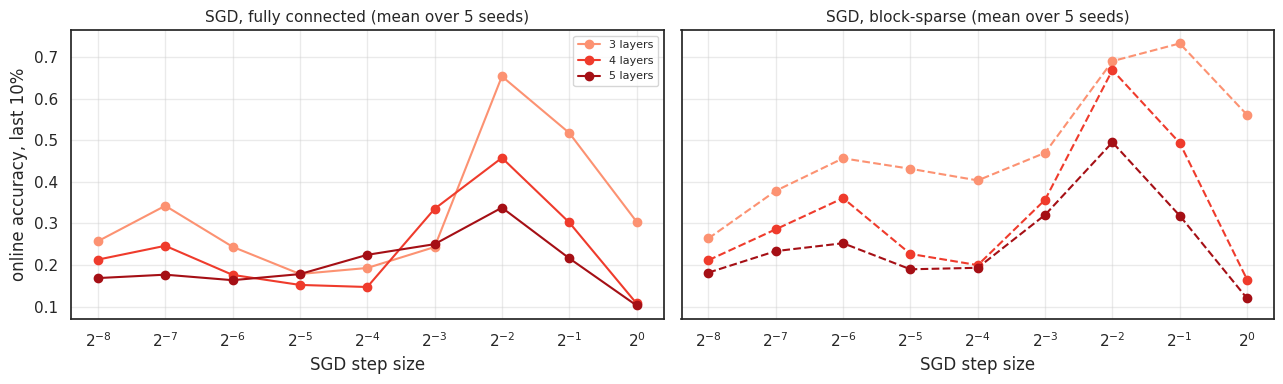

3 layers, fully connected: 2^-8 25.71%, 2^-7 34.23%, 2^-6 24.37%, 2^-5 17.83%, 2^-4 19.28%, 2^-3 24.31%, 2^-2 65.33%, 2^-1 51.73%, 2^0 30.41%; best 2^-2
3 layers, block-sparse: 2^-8 26.38%, 2^-7 37.82%, 2^-6 45.63%, 2^-5 43.12%, 2^-4 40.32%, 2^-3 46.95%, 2^-2 68.98%, 2^-1 73.24%, 2^0 56.08%; best 2^-1
4 layers, fully connected: 2^-8 21.29%, 2^-7 24.61%, 2^-6 17.62%, 2^-5 15.21%, 2^-4 14.71%, 2^-3 33.49%, 2^-2 45.74%, 2^-1 30.22%, 2^0 10.76%; best 2^-2
4 layers, block-sparse: 2^-8 21.15%, 2^-7 28.57%, 2^-6 36.06%, 2^-5 22.66%, 2^-4 19.96%, 2^-3 35.67%, 2^-2 66.84%, 2^-1 49.32%, 2^0 16.49%; best 2^-2
5 layers, fully connected: 2^-8 16.85%, 2^-7 17.67%, 2^-6 16.35%, 2^-5 17.81%, 2^-4 22.44%, 2^-3 25.00%, 2^-2 33.78%, 2^-1 21.61%, 2^0 10.28%; best 2^-2
5 layers, block-sparse: 2^-8 18.17%, 2^-7 23.34%, 2^-6 25.22%, 2^-5 18.96%, 2^-4 19.32%, 2^-3 32.04%, 2^-2 49.48%, 2^-1 31.84%, 2^0 11.97%; best 2^-2


In [7]:
sweeps, best_exponent = {}, {}
for n_layers in DEPTHS:
    sweeps[n_layers], best_exponent[n_layers] = tune_sgd(n_layers)

fig, axes = plt.subplots(1, len(NETWORKS), figsize=(13, 4), sharex=True, sharey=True)
for ax, network in zip(axes, NETWORKS):
    for n_layers, color in zip(DEPTHS, ('#fc9272', '#ef3b2c', '#a50f15')):
        sweep = sweeps[n_layers][network]
        ax.plot(list(sweep), [final_accuracy(r).mean() for r in sweep.values()], color=color, marker='o', lw=1.5,
                ls='--' if network == 'block-sparse' else '-', label=f'{n_layers} layers')
    ax.set_xlabel('SGD step size')
    ax.set_title(f'SGD, {network} (mean over {SWEEP_SEEDS} seeds)', fontsize=11)
    ax.grid(alpha=0.4)
exponents = sorted({e for by_network in sweeps.values() for sweep in by_network.values() for e in sweep})
axes[0].set_xticks(range(exponents[0], exponents[-1] + 1))
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda e, _: f'$2^{{{e:g}}}$'))
axes[0].yaxis.set_major_locator(plt.MultipleLocator(0.1))
axes[0].set_ylabel('online accuracy, last 10%')
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

for n_layers in DEPTHS:
    for network, sweep in sweeps[n_layers].items():
        accuracies = ', '.join(f'2^{e} {final_accuracy(r).mean():.2%}' for e, r in sweep.items())
        print(f'{n_layers} layers, {network}: {accuracies}; best 2^{best_exponent[n_layers][network]}')

## Main runs

Ours and SGD (at its best step size for each network) on both networks, at each depth (mean ± 2 SE over seeds).
Blue: ours; red: SGD; dashed: block-sparse.

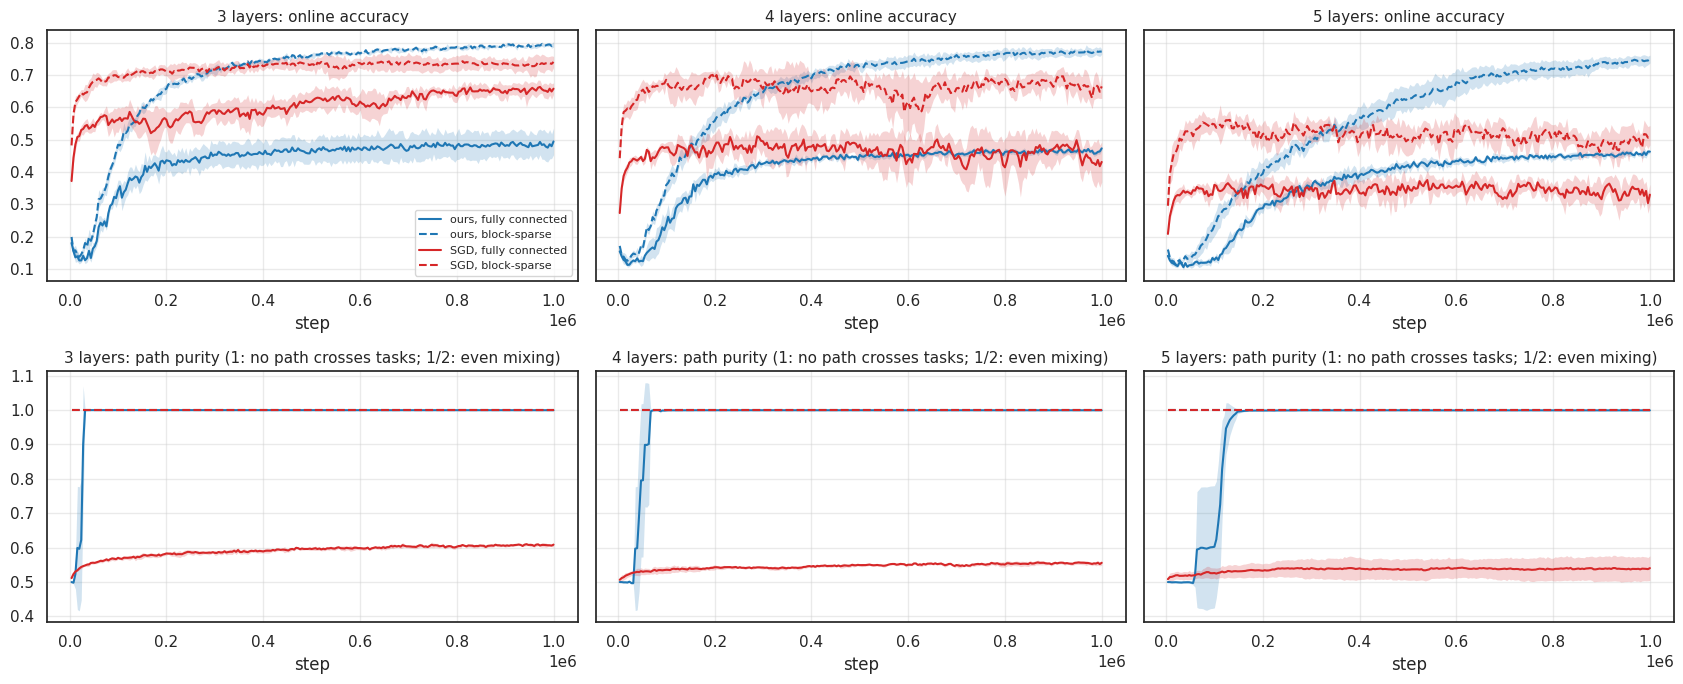

--- 3 layers (SGD step sizes: fully connected 2^-2, block-sparse 2^-1) ---
ours, fully connected   online accuracy 48.40% (tasks 53.0%, 43.8%); a task below 15% in 4 of 5 seeds
ours, block-sparse      online accuracy 79.06% (tasks 79.0%, 79.1%); a task below 15% in 0 of 5 seeds
SGD, fully connected    online accuracy 65.33% (tasks 67.4%, 63.2%); a task below 15% in 0 of 5 seeds
SGD, block-sparse       online accuracy 73.24% (tasks 70.9%, 75.6%); a task below 15% in 0 of 5 seeds
H1, ours, fully connected vs ours, block-sparse: -30.7 points (± 4.2): failed
H2, ours, block-sparse vs SGD, block-sparse: +5.8 points (± 2.5): held
H3, SGD, fully connected vs SGD, block-sparse: -7.9 points (± 3.1): held
--- 4 layers (SGD step sizes: fully connected 2^-2, block-sparse 2^-2) ---
ours, fully connected   online accuracy 46.40% (tasks 53.5%, 39.3%); a task below 15% in 5 of 5 seeds
ours, block-sparse      online accuracy 77.02% (tasks 76.9%, 77.1%); a task below 15% in 0 of 5 seeds
SGD, fully conne

In [8]:
window_ends = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)


def plot_runs(runs, colors, dashed=()):
    # Accuracy and path purity over training at each depth, for each run in runs[n_layers] (mean +- 2 SE over seeds),
    # drawn in `colors[label]`, and dashed for the labels in `dashed`.
    fig, axes = plt.subplots(2, len(DEPTHS), figsize=(17, 7), sharey='row')
    for column, n_layers in enumerate(DEPTHS):
        for row, (key, title) in enumerate([('accuracy', 'online accuracy'),
                                            ('purity', 'path purity (1: no path crosses tasks; 1/2: even mixing)')]):
            ax = axes[row, column]
            for label, res in runs[n_layers].items():
                mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
                ax.plot(window_ends, mean, color=colors[label], ls='--' if label in dashed else '-', lw=1.5,
                        label=label)
                ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
            ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
            ax.set_xlabel('step')
            ax.set_title(f'{n_layers} layers: {title}', fontsize=11)
            ax.grid(alpha=0.4)
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def report(runs, tests):
    # Prints every run's accuracy, each task's accuracy (mean over seeds) and the number of seeds in which a task is
    # below NEAR_CHANCE, all over the last FINAL_FRACTION. Then for each test (name, label, reference, claim) the
    # per-seed gap of `label` to `reference` (mean and 2 SE over paired seeds), and whether the claim held: 'within'
    # ACCURACY_TOLERANCE of it (at most that far below), or more than that 'below' or 'above' it.
    width = max(map(len, runs))
    for label, res in runs.items():
        tasks = res['task accuracy'][:, final].mean(1)                            # (seed, task)
        print(f'{label:<{width}}   online accuracy {final_accuracy(res).mean():.2%} (tasks '
              + ', '.join(f'{a:.1%}' for a in tasks.mean(0))
              + f'); a task below {NEAR_CHANCE:.0%} in {(tasks < NEAR_CHANCE).any(1).sum()} of {len(tasks)} seeds')
    for name, label, reference, claim in tests:
        g = final_accuracy(runs[label]) - final_accuracy(runs[reference])
        ok = {'within': g.mean() >= -ACCURACY_TOLERANCE, 'below': g.mean() < -ACCURACY_TOLERANCE,
              'above': g.mean() > ACCURACY_TOLERANCE}[claim]
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.1f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}): {"held" if ok else "failed"}')


runs = {}
for n_layers in DEPTHS:
    ours = run(n_layers, True)
    sgd = run(n_layers, False, [2.0 ** best_exponent[n_layers][network] for network in NETWORKS])
    runs[n_layers] = {**{f'ours, {k}': v for k, v in ours.items()}, **{f'SGD, {k}': v for k, v in sgd.items()}}
labels = list(runs[DEPTHS[0]])
plot_runs(runs, {label: 'tab:blue' if label.startswith('ours') else 'tab:red' for label in labels},
          dashed=[label for label in labels if label.endswith('block-sparse')])

for n_layers in DEPTHS:
    step_sizes = ', '.join(f'{network} 2^{e}' for network, e in best_exponent[n_layers].items())
    print(f'--- {n_layers} layers (SGD step sizes: {step_sizes}) ---')
    report(runs[n_layers], [('H1', 'ours, fully connected', 'ours, block-sparse', 'within'),
                            ('H2', 'ours, block-sparse', 'SGD, block-sparse', 'within'),
                            ('H3', 'SGD, fully connected', 'SGD, block-sparse', 'below')])

## Results

- **H1 failed at every depth, by about 30 points.** Fully connected, ours reaches 48.4%, 46.4% and 45.5% online
  accuracy with 3, 4 and 5 layers, against 79.1%, 77.0% and 74.1% block-sparse: −30.7 (± 4.2), −30.6 (± 1.2) and
  −28.6 (± 1.1) points (2 SE over paired seeds). With 2 layers (05) the gap was −5.0.
- **H2 held at every depth.** Block-sparse, ours is above SGD at its best step size by +5.8 (± 2.5), +10.2 (± 2.0) and
  +24.6 (± 3.6) points; SGD reaches 73.2%, 66.8% and 49.5% (step sizes $2^{-1}$, $2^{-2}$, $2^{-2}$). From 3 to 5
  layers ours loses 5 points and SGD 24. SGD learns fast, then levels off (and slowly declines with 4 and 5 layers);
  with 5 layers ours is still rising at the end.
- **H3 held at every depth.** Fully connected, SGD (best step size $2^{-2}$ at every depth) reaches 65.3%, 45.7% and
  33.8%: −7.9 (± 3.1), −21.1 (± 3.8) and −15.7 (± 6.5) points below SGD block-sparse. Against ours fully connected
  it is 17 points better with 3 layers, level with 4 (45.7% against 46.4%), and 12 points worse with 5.
- Two things favour SGD in H2. Its main runs use the 5 seeds it was tuned on, so its numbers are the best of 9 on
  those seeds. And the powers-of-2 grid is coarse around a sharp peak (block-sparse with 4 layers: 35.7%, 66.8% and
  49.3% at $2^{-3}$, $2^{-2}$ and $2^{-1}$), so a finer grid might gain it a few points, against margins of 5.8 points
  and more. Every sweep had its best inside the starting grid ($2^{-8}$ to $2^0$), so none was extended.
- **Diagnostics: fully connected, ours fails by allocation, not by mixing.** Its path purity reaches 1 within
  about 30k, 70k and 150k steps, but it reads 1 because one task gets almost no paths: a task stays near chance
  (below 15% over the last 10%) in 4, 5 and 5 of the 5 seeds with 3, 4 and 5 layers, so the overall 45–48% is about
  the mean of 10% and 80%. (Each task's mean over seeds, e.g. 53.0% and 43.8% with 3 layers, averages over which task
  is dropped.) This is 05's uneven split of the hidden units, taken to the extreme. SGD fully connected does the
  opposite: it keeps both tasks (a task near chance in 0, 0 and 2 of 5 seeds) but mixes them, with path purity
  about 0.6, 0.55 and 0.55 at the end. No block-sparse run leaves a task near chance.

## Part 2: generate and test across all hidden layers

Does generate and test across all hidden layers, alone or with shadow weights, recover block-sparse performance at
depth? Ours on the fully connected network with generate and test, without and with shadow weights (blue shades),
against Part 1's ours fully connected (red) and block-sparse (gray), at each depth (mean ± 2 SE over seeds).

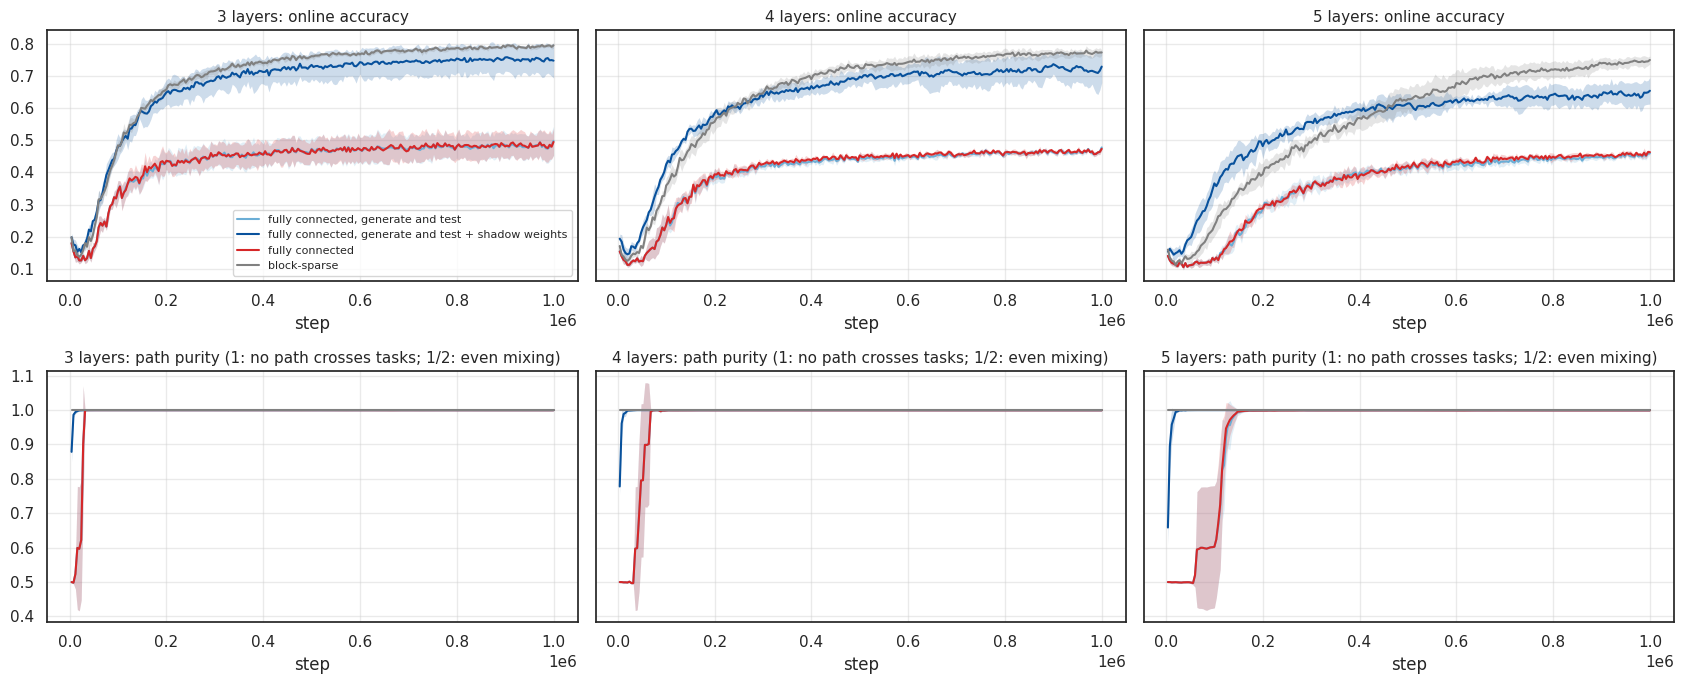

--- 3 layers ---
fully connected, generate and test                    online accuracy 48.21% (tasks 52.8%, 43.6%); a task below 15% in 4 of 5 seeds
fully connected, generate and test + shadow weights   online accuracy 75.04% (tasks 68.8%, 81.3%); a task below 15% in 0 of 5 seeds
fully connected                                       online accuracy 48.40% (tasks 53.0%, 43.8%); a task below 15% in 4 of 5 seeds
block-sparse                                          online accuracy 79.06% (tasks 79.0%, 79.1%); a task below 15% in 0 of 5 seeds
H4, fully connected, generate and test vs fully connected: -0.2 points (± 0.2): failed
H5, fully connected, generate and test + shadow weights vs block-sparse: -4.0 points (± 4.5): failed
--- 4 layers ---
fully connected, generate and test                    online accuracy 46.27% (tasks 53.6%, 39.0%); a task below 15% in 5 of 5 seeds
fully connected, generate and test + shadow weights   online accuracy 72.04% (tasks 77.0%, 67.0%); a task below 15% in

In [9]:
gnt_runs = {n_layers: {'fully connected, generate and test': run_gnt(n_layers, shadow=False),
                       'fully connected, generate and test + shadow weights': run_gnt(n_layers, shadow=True),
                       'fully connected': runs[n_layers]['ours, fully connected'],
                       'block-sparse': runs[n_layers]['ours, block-sparse']}
            for n_layers in DEPTHS}
plot_runs(gnt_runs, {'fully connected, generate and test': '#6baed6',
                     'fully connected, generate and test + shadow weights': '#08519c',
                     'fully connected': 'tab:red', 'block-sparse': 'gray'})

for n_layers in DEPTHS:
    print(f'--- {n_layers} layers ---')
    report(gnt_runs[n_layers], [('H4', 'fully connected, generate and test', 'fully connected', 'above'),
                                ('H5', 'fully connected, generate and test + shadow weights', 'block-sparse',
                                 'within')])

**Results.**

- **H4 failed at every depth.** Generate and test leaves ours fully connected where it was: 48.2%, 46.3% and 45.1%
  with 3, 4 and 5 layers, −0.2 (± 0.2), −0.1 (± 0.3) and −0.4 (± 0.2) points from Part 1's run without it. Its curves
  lie on top of that run's, and a task still stays near chance in 4, 5 and 5 of the 5 seeds.
- **H5 failed at every depth.** With shadow weights as well, ours fully connected reaches 75.0%, 72.0% and 64.4%:
  −4.0 (± 4.5), −5.0 (± 4.1) and −9.7 (± 4.4) points from block-sparse. That recovers most of the 30-point gap with 3
  and 4 layers, and two thirds of it with 5. The gaps vary widely between seeds.
- With shadow weights, no seed leaves a task near chance at any depth, and path purity reaches 1 within about 10–20k
  steps, so the units no longer abandon a task. But the tasks still end uneven: each task's mean over seeds is 68.8%
  and 81.3%, 77.0% and 67.0%, and 75.0% and 53.7% with 3, 4 and 5 layers, while block-sparse keeps them within 0.6
  points of each other.
- With 4 and 5 layers, generate and test + shadow weights learns faster than block-sparse at first (ahead until about
  200k and 400k steps), then levels off below it.